In [1]:
import sys
sys.path.insert(1, '/home/santolam/MyPythonLibrary/MAR-RECAP/libmar/')
import climbasis as climb
from climbasis import *
import domain as dom
import myplot
import numpy.ma as ma
from myplot import *
import obsinfo as obs
from obsinfo import *



In [2]:
domainM='GRq'; nx=ny=10
ds_RF_raw=xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/MARout_post/GRq/spin2/work/daily/'+
    'RF_day_MARv3.14_ER5_spin2_GRq_1980-2024.nc')['RF']#.sel(ZTQLEV=2)
ds_RF= ds_RF_raw.rename({'TIME': 'time'})
ds_RF=ds_RF[:,ny:-ny,nx:-nx]

ds_SF_raw=xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/MARout_post/GRq/spin2/work/daily/'+
    'SF_day_MARv3.14_ER5_spin2_GRq_1980-2024.nc')['SF']#.sel(ZTQLEV=2)
ds_SF= ds_SF_raw.rename({'TIME': 'time'})
ds_SF=ds_SF[:,ny:-ny,nx:-nx]

In [3]:
ds_TF=ds_RF+ds_SF


In [4]:
## Model MAR
domain='GRc'
sourceDataGrid='/home/santolam/'
fileName_grM='NST.2000.01.01.00.GRc.nc'
dsM= xr.open_dataset(sourceDataGrid+fileName_grM)
LONS=dsM.LON[ny:-ny,nx:-nx].values;LATS=dsM.LAT[ny:-ny,nx:-nx].values
dsSH=dsM.SH[ny:-ny,nx:-nx];dsICE=dsM.ICE[ny:-ny,nx:-nx]

dsSH=dsSH.rename({'y': 'Y','x':'X'})

In [55]:
lon_min,lon_max=LONS.min(),LONS.max()
print(lon_min)
lat_min,lat_max=LATS.min(),LATS.max()
print(lat_min)

82.524
26.566393


In [5]:
#ds_TF=ds_SF+ds_RF

In [6]:
####
##Donnes meteo
sourceData='/bettik/PROJECTS/pr-regional-climate/santolam/glacioclim/donnees_precip/'
#
#Precipitation_Khare_corrected_Nov2016_Nov2023_final.xlsx
#Precipitation_Pyramid_Pheriche_corrected_Apr2016_Nov2023_final.xlsx
#Precipitation_Pyramid_Pheriche_corrected_Dec2012_Apr2016_final.xlsx

In [7]:
#https://github.com/Andeol-ramb/MAR_HMA_GLACIOCLIM_Comparisons/blob/main/Sensitivity_Test_MAR/Sensitivity_Test_Pyramide_Precip.ipynb
####
## Opening Pheriche+Khare
####

sourceDataSta=sourceData#'/Users/santolam/Data/glacioclim/donnees_precip/'
path1 =sourceDataSta+"/Precipitation_Pyramid_Pheriche_corrected_Dec2012_Apr2016_final.xlsx"
xl_data1=pd.ExcelFile(path1)

dfs1= {sheet_name: xl_data1.parse(sheet_name) 
       for sheet_name in xl_data1.sheet_names}

DataPyramid_Pheriche12_16=dfs1['Precip_data_Dec12_Apr16']

NameVarsPP12_16=['TimeY','RRYhourly','RRYcumul','TimeH','RRHhourly','RRHcumul']
UnitVarsPP16_23=['data/hour','mm','mm','data/hour','mm','mm',]

dfile1P12_16= pd.DataFrame(data=DataPyramid_Pheriche12_16.loc[10:])
df1P12_16=pd.DataFrame(dfile1P12_16.values, columns=NameVarsPP12_16)

df1P12_16['TimeY'] = df1P12_16['TimeY'].dt.round('h')

path =sourceDataSta+"/Precipitation_Pyramid_Pheriche_corrected_Apr2016_Nov2023_final.xlsx"
xl_data=pd.ExcelFile(path)

dfs = {sheet_name: xl_data.parse(sheet_name) 
       for sheet_name in xl_data.sheet_names}
DataPyramid_Pheriche16_23=dfs['Precip_data_Apr16_Nov23']

NameVarsPP16_23=['TimeY','TairY','uY','RHY','WMOphaseY','RRYhourly','RRYcumul','TimeH','TairH','uH','RHh','WMOphaseH','RRHhourly','RRHcumul']
UnitVarsPP16_23=['data/hour','(°C)','(ms-1)','(%)','mm','mm','data/hour','(°C)','(ms-1)','(%)','mm','mm',]

dfile1P16_23= pd.DataFrame(data=DataPyramid_Pheriche16_23.loc[10:57630]) #3399 marche, Toujours la même taille jusque 3399 puis toujours lenght var=t-1 par la suite 
#CHANGEMENT DANS TIME:3389 	2016-09-15 17:59:59.!999! / 2016-09-15 18:59:59.!998! 
#donc erreur à chaque changement de décimale, corriger cette data avant tout autre chose


dfile2P16_23=pd.DataFrame(data=DataPyramid_Pheriche16_23.loc[57632:]) 
df1P16_23=pd.DataFrame(dfile1P16_23.values, columns=NameVarsPP16_23)
df2P16_23=pd.DataFrame(dfile2P16_23.values, columns=NameVarsPP16_23)
df1P16_23['TimeY'] = df1P16_23['TimeY'].dt.round('h')
df2P16_23['TimeY'] = df2P16_23['TimeY'].dt.round('30min')

#Definition d'une fréquence permettant par la suite le traitement avec des Xarray
def NewTime(df, NameVar, values, freq):
    time = pd.to_datetime(df['TimeY'].values)
    ds = xr.Dataset({NameVar: ("time", np.asarray(values))}, coords={"time": time})
    return ds
# Time step: 1h

RR1_PY=[float(thing) for thing in df1P12_16['RRYhourly'].values]
RRY1_PY = [float(thing) for thing in df1P16_23['RRYhourly'].values]
dsY1_PY = NewTime(df1P16_23, 'RRYhourly', RRY1_PY, '1h')
dsRR1_PY= NewTime(df1P12_16, 'RRYhourly', RR1_PY, '1h')

# Time step : 30 min 
RRY2_PY = [float(thing) for thing in df2P16_23['RRYhourly'].values]
dsY2_PY = NewTime(df2P16_23, 'RRYhourly', RRY2_PY, '30min')
RR_PY = xr.concat([dsRR1_PY,dsY1_PY, dsY2_PY], dim='time')


RR1_PH=[float(thing) for thing in df1P12_16['RRHhourly'].values]
RRY1_PH = [float(thing) for thing in df1P16_23['RRHhourly'].values]
dsY1_PH = NewTime(df1P16_23, 'RRHhourly', RRY1_PH, '1h')
dsRR1_PH= NewTime(df1P12_16, 'RRHhourly', RR1_PH, '1h')

# Time step : 30 min 
RRY2_PH = [float(thing) for thing in df2P16_23['RRHhourly'].values]
dsY2_PH = NewTime(df2P16_23, 'RRHhourly', RRY2_PH, '30min')
RR_PH = xr.concat([dsRR1_PH,dsY1_PH, dsY2_PH], dim='time')

#####
#
#Khare
#
#####
fileName_KH='Precipitation_Khare_corrected_Nov2016_Nov2023_final.xlsx'
xl_file_KH = pd.ExcelFile(sourceDataSta+fileName_KH)
print(xl_file_KH)
#
dfs_KH = {sheet_name: xl_file_KH.parse(sheet_name) 
          for sheet_name in xl_file_KH.sheet_names}

NameVars_KH=['Time','Tair' ,'u' ,'RH', 'Phase_WMO','RR_WMO_Half-hourly_values','RR_WMO_Khare_cumulated']
UnitVars_KH=['time','(°C)','(ms-1)','(%)','phase','mm w.e.','mm w.e.']

##Define new DataFrame and changing name of columns
dfile_KH = pd.DataFrame(data=dfs_KH["Precip_data_Nov16_Nov23"].loc[8:])
df_KH=pd.DataFrame(dfile_KH.values, columns=NameVars_KH)

path =sourceDataSta+fileName_KH
xl_data=pd.ExcelFile(path)
dfs = {sheet_name: xl_data.parse(sheet_name) 
       for sheet_name in xl_data.sheet_names}
DataKhare16_23=dfs['Precip_data_Nov16_Nov23']
NameVarsPP16_23=['Time','Tair','u','RH','WMOphase','RRhourly','RRcumul']
UnitVarsPP16_23=['data/hour','(°C)','(ms-1)','(%)','mm','mm']
dfileP16_23= pd.DataFrame(data=DataKhare16_23.loc[10:])
dfP16_23=pd.DataFrame(dfileP16_23.values, columns=NameVarsPP16_23)

RR_KH=[float(i) for i in dfP16_23.RRhourly.values] 
def NewTime(df, NameVar, values, freq):
    time = pd.to_datetime(df['Time'].values)
    ds = xr.Dataset({NameVar: ("time", np.asarray(values))}, coords={"time": time})
    return ds
RR_KH=NewTime(dfP16_23,'RRhourly',RR_KH,'30min')
#RR=RR.sel(time=slice('2016'))


rr_daily_PY=RR_PY.resample(time='D').sum()
rr_daily_PY=rr_daily_PY.RRYhourly

rr_daily_PH=RR_PH.resample(time='D').sum()
rr_daily_PH=rr_daily_PH.RRHhourly

rr_daily_KH=RR_KH.resample(time='D').sum()
rr_daily_KH=rr_daily_KH.RRhourly

idatePY = str(rr_daily_PY.time[0].values)[:10]
fdatePY = str(rr_daily_PY.time[-1].values)[:10]
idatePH = str(rr_daily_PH.time[0].values)[:10]
fdatePH = str(rr_daily_PH.time[-1].values)[:10]
idateKH = str(rr_daily_KH.time[0].values)[:10]
fdateKH = str(rr_daily_KH.time[-1].values)[:10]


In [8]:
###
## PYRAMID Salerno
### 

In [9]:
sourceData='/bettik/PROJECTS/pr-regional-climate/santolam/PYRAMID_NETWORK_DATA_v3/'

file_AWS0='AWS0_Z5035_Lvl1.csv'
file_AWS1='AWS1_Z5035_Lvl1.csv'
file_AWS2='AWS2_Z4260_Lvl1.csv'
file_AWS3='AWS3_Z2660_Lvl1.csv'
file_AWS4='AWS4_Z5600_Lvl1.csv'
file_AWS5='AWS5_Z3570_Lvl1.csv'
file_AWSSC='AWSSC_Z7986_Lvl1.csv'
file_CNG='CNG_SNP_Z5700_Lvl1.csv'
file_mon_Pyr='Pyramid_Z5035_lvl2.csv'

# Store filenames in a dictionary for easy looping
files = {
    'AWS0': file_AWS0,
    'AWS1': file_AWS1,
    'AWS2': file_AWS2,
    'AWS3': file_AWS3,
    'AWS4': file_AWS4,
    'AWS5': file_AWS5,
    'AWSSC': file_AWSSC,
    'CNG': file_CNG,
    #'Pyramid': file_mon_Pyr
}
dfs = {}
for name, fname in files.items():
    path = os.path.join(sourceData, fname)
    
    # Read semicolon-delimited CSV
    df = pd.read_csv(path, sep=';')
    
    # Combine into datetime
    df['TIMESTAMP'] = pd.to_datetime(dict(
        year=df['year'],
        month=df['month'],
        day=df['day'],
        hour=df['hour']
    ))
    
    # Set datetime index and drop date columns
    df.set_index('TIMESTAMP', inplace=True)
    df.drop(columns=['year', 'month', 'day', 'hour'], inplace=True)
    
    # Replace physically impossible values (< -100) with NaN
    df[df < -100] = np.nan
    
    # Store
    dfs[name] = df
    
# Optional: unpack for direct access
df_AWS0  = dfs['AWS0']
df_AWS1  = dfs['AWS1']
df_AWS2  = dfs['AWS2']
df_AWS3  = dfs['AWS3']
df_AWS4  = dfs['AWS4']
df_AWS5  = dfs['AWS5']
df_AWSSC = dfs['AWSSC']
df_CNG   = dfs['CNG']
#df_Pyr   = dfs['Pyramid']

# Quick check
print(df_AWS0.head())

# Daily total precipitation (sum of hourly rates)
rr_AWS0_daily = df_AWS0['RR'].resample('D').sum()
rr_AWS1_daily = df_AWS1['RR'].resample('D').sum()
rr_AWS2_daily = df_AWS2['RR'].resample('D').sum()
rr_AWS3_daily = df_AWS3['RR'].resample('D').sum()
rr_AWS4_daily = df_AWS4['RR'].resample('D').sum()
rr_AWS5_daily = df_AWS5['RR'].resample('D').sum()


                       AT   RR     AP    RH    WS  WD
TIMESTAMP                                            
1994-01-01 02:00:00 -11.9  0.0  551.4  25.0  0.00 NaN
1994-01-01 04:00:00 -13.2  0.0  551.0  23.0  0.00 NaN
1994-01-01 06:00:00 -10.5  0.0  551.1  10.0  0.26 NaN
1994-01-01 08:00:00 -10.9  0.0  551.9  17.0  0.00 NaN
1994-01-01 10:00:00  -7.1  0.0  553.1  17.0  5.58 NaN


In [10]:
sourceData='/bettik/PROJECTS/pr-regional-climate/santolam/nat_geo_stations_everest/'
#sourceData='/Users/santolam/Desktop/nat_geo_stations_everest/'
##
file_bc='Base_Camp_20230630.csv'
file_c2='Camp2_20230630.csv'
file_phort='Phortse_20230630.csv'
file_bish='Bishop_Rock_20230630.csv'
file_sc='South_Col_20230630.csv'

df_bc = pd.read_csv(os.path.join(sourceData, file_bc), parse_dates=['TIMESTAMP'])
df_c2 = pd.read_csv(os.path.join(sourceData, file_c2), parse_dates=['TIMESTAMP'])
df_phort = pd.read_csv(os.path.join(sourceData, file_phort), parse_dates=['TIMESTAMP'])
df_bish = pd.read_csv(os.path.join(sourceData, file_bish), parse_dates=['TIMESTAMP'])
df_sc = pd.read_csv(os.path.join(sourceData, file_sc), parse_dates=['TIMESTAMP'])

# Optional: set timestamp as index
for df in [df_bc, df_c2, df_phort, df_bish, df_sc]:
    df.set_index('TIMESTAMP', inplace=True)

# Quick check
print(df_bc.head())

rr_bc_daily = df_bc['PRECIP'].resample('D').sum()
rr_phort_daily = df_phort['PRECIP'].resample('D').sum()


                     T_HMP      RH   PRESS  PRECIP
TIMESTAMP                                         
2019-10-17 13:00:00 -4.078  99.578  536.71     0.0
2019-10-17 14:00:00 -4.282  92.273  537.15     0.0
2019-10-17 15:00:00 -3.584  86.358  537.28     0.0
2019-10-17 16:00:00 -3.458  88.629  537.25     0.0
2019-10-17 17:00:00 -3.966  74.045  537.22     0.0


In [11]:
###Coordinates

In [12]:
import pandas as pd
from pyproj import Transformer

# Define the transformer (UTM Zone 45N → WGS84)
transformer = Transformer.from_crs("epsg:32645", "epsg:4326", always_xy=True)

# --- Coordinates conversions (you already have some precomputed) ---
# MN (Mera North)
eastingMN, northingMN = 489885, 3065938
lon_MN, lat_MN = transformer.transform(eastingMN, northingMN)
elev_MN = 5360

# CH (Changri)
lon_CH, lat_CH, elev_CH = 86.77948450, 27.98336311, 5360

# ML (Merala)
lon_ML, lat_ML, elev_ML = 86.900, 27.735, 5352.008

# KH (Khare)
lon_KH, lat_KH, elev_KH = 86.8776142768303, 27.74424682282522, 4888

# PH (Pheriche)
lon_PH, lat_PH, elev_PH = 86.81972903284355, 27.895048949594884, 4260

# PY (Pyramid)
lon_PY, lat_PY, elev_PY = 86.81296905961787, 27.957821815535848, 5035

# MS (Mera South)
eastingMS, northingMS = 487553.653, 3064704.231
lon_MS, lat_MS = transformer.transform(eastingMS, northingMS)
elev_MS = 5360  # estimated same as MN, if not otherwise specified

# MC (Mera Central)
eastingMC, northingMC = 488409.424, 3066148.049
lon_MC, lat_MC = transformer.transform(eastingMC, northingMC)
elev_MC = 5770

# --- Define metadata list ---
stations_info_glacioclim = [
    {"ID": "MN", "Name": "Mera Naulek", "Lat": lat_MN, "Lon": lon_MN, "Elev_m": elev_MN, "Timestep": "1h"},
    {"ID": "CH", "Name": "Changri", "Lat": lat_CH, "Lon": lon_CH, "Elev_m": elev_CH, "Timestep": "1h"},
    {"ID": "ML", "Name": "Mera La", "Lat": lat_ML, "Lon": lon_ML, "Elev_m": elev_ML, "Timestep": "1h"},
    {"ID": "KH", "Name": "Khare", "Lat": lat_KH, "Lon": lon_KH, "Elev_m": elev_KH, "Timestep": "1h"},
    {"ID": "PH", "Name": "Pheriche", "Lat": lat_PH, "Lon": lon_PH, "Elev_m": elev_PH, "Timestep": "1h"},
    {"ID": "PY", "Name": "Pyramid", "Lat": lat_PY, "Lon": lon_PY, "Elev_m": elev_PY, "Timestep": "1h"},
    {"ID": "MS", "Name": "Mera Summir", "Lat": lat_MS, "Lon": lon_MS, "Elev_m": elev_MS, "Timestep": "1h"},
    {"ID": "MC", "Name": "Mera Camp 5770", "Lat": lat_MC, "Lon": lon_MC, "Elev_m": elev_MC, "Timestep": "1h"},
]

# --- Create DataFrame ---
df_stations_glacioclim = pd.DataFrame(stations_info_glacioclim)

# Display neatly
print(df_stations_glacioclim.to_string(index=False, justify='center', col_space=12))


     ID           Name           Lat          Lon        Elev_m      Timestep  
     MN         Mera Naulek  27.717723    86.897390     5360.000        1h     
     CH             Changri  27.983363    86.779484     5360.000        1h     
     ML             Mera La  27.735000    86.900000     5352.008        1h     
     KH               Khare  27.744247    86.877614     4888.000        1h     
     PH            Pheriche  27.895049    86.819729     4260.000        1h     
     PY             Pyramid  27.957822    86.812969     5035.000        1h     
     MS         Mera Summir  27.706566    86.873753     5360.000        1h     
     MC      Mera Camp 5770  27.719608    86.882420     5770.000        1h     


In [13]:
##
# --- AWS and related station metadata ---

# AWSSC (South Col)
lat_AWSSC, lon_AWSSC, elev_AWSSC = 27.98, 86.76, 7986

# CNG_SNP (Changri Nup)
lat_CNG, lon_CNG, elev_CNG = 27.96, 86.93, 5700

# AWS0 (Pyramid)
lat_AWS0, lon_AWS0, elev_AWS0 = 27.96, 86.81, 5035

# AWS1 (Pyramid)
lat_AWS1, lon_AWS1, elev_AWS1 = 27.96, 86.81, 5035

# AWS2 (Pheriche)
lat_AWS2, lon_AWS2, elev_AWS2 = 27.90, 86.82, 4260

# AWS3 (Lukla)
lat_AWS3, lon_AWS3, elev_AWS3 = 27.70, 86.72, 2660

# AWS4 (Kala Patthar)
lat_AWS4, lon_AWS4, elev_AWS4 = 27.99, 86.83, 5600

# AWS5 (Namche)
lat_AWS5, lon_AWS5, elev_AWS5 = 27.80, 86.71, 3570

# Pyramid (monthly level 2)
lat_Pyr, lon_Pyr, elev_Pyr = 27.96, 86.81, 5035

# Define metadata as a list of dicts
stations_info_salerno = [
    {"ID": "AWSSC", "Name": "South Col", "Lat": 27.98, "Lon": 86.76, "Elev_m": 7986, "Timestep": "1h"},
    {"ID": "CNG_SNP", "Name": "Changri Nup", "Lat": 27.96, "Lon": 86.93, "Elev_m": 5700, "Timestep": "1h"},
    {"ID": "AWS0", "Name": "Pyramid", "Lat": 27.96, "Lon": 86.81, "Elev_m": 5035, "Timestep": "1h"},
    {"ID": "AWS1", "Name": "Pyramid", "Lat": 27.96, "Lon": 86.81, "Elev_m": 5035, "Timestep": "1h"},
    {"ID": "AWS2", "Name": "Pheriche", "Lat": 27.90, "Lon": 86.82, "Elev_m": 4260, "Timestep": "1h"},
    {"ID": "AWS3", "Name": "Lukla", "Lat": 27.70, "Lon": 86.72, "Elev_m": 2660, "Timestep": "1h"},
    {"ID": "AWS4", "Name": "Kala Patthar", "Lat": 27.99, "Lon": 86.83, "Elev_m": 5600, "Timestep": "1h"},
    {"ID": "AWS5", "Name": "Namche", "Lat": 27.80, "Lon": 86.71, "Elev_m": 3570, "Timestep": "1h"},
    {"ID": "PYmon", "Name": "Pyramid (monthly)", "Lat": 27.96, "Lon": 86.81, "Elev_m": 5035, "Timestep": "1month"},
]

# Create DataFrame
df_stations_salerno = pd.DataFrame(stations_info_salerno)

# Display
print(df_stations_salerno)

        ID               Name    Lat    Lon  Elev_m Timestep
0    AWSSC          South Col  27.98  86.76    7986       1h
1  CNG_SNP        Changri Nup  27.96  86.93    5700       1h
2     AWS0            Pyramid  27.96  86.81    5035       1h
3     AWS1            Pyramid  27.96  86.81    5035       1h
4     AWS2           Pheriche  27.90  86.82    4260       1h
5     AWS3              Lukla  27.70  86.72    2660       1h
6     AWS4       Kala Patthar  27.99  86.83    5600       1h
7     AWS5             Namche  27.80  86.71    3570       1h
8    PYmon  Pyramid (monthly)  27.96  86.81    5035   1month


In [14]:
#Nat geo
#BASE CAMP AWS (27.9952 N, 86.8406 E, 5315 M ASL)
lat_bc,lon_bs,elev_bc=27.9952, 86.8406, 5315
#CAMP II AWS (27.9810 N, 86.9023 E, 6464 M ASL)
lat_c2,lon_c2,elev_c2=27.9810, 86.9023, 6464 
#PHORTSE AWS (27.8456 N, 86.7472 E, 3810 M ASL)
lat_phort,lon_phort,elev_phort=27.8456, 86.7472, 3810 
#BISHOP ROCK AWS (27.9735 N, 86.9308 E, 8810 M ASL)
lat_bish,lon_bish,elev_bish=27.9735, 86.9308, 8810 
#MT. EVEREST SOUTH COL AWS (27.9719 N, 86.9295 E, 7945 M ASL)
lat_sc,lon_sc,elev_sc=27.9719, 86.9295, 7945


# Define metadata for Everest AWS network
stations_info_everest = [
    {"ID": "bc", "Name": "BaseCampAWS", "Lat": 27.9952, "Lon": 86.8406, "Elev_m": 5315},
    {"ID": "c2", "Name": "Camp II AWS", "Lat": 27.9810, "Lon": 86.9023, "Elev_m": 6464},
    {"ID": "phort", "Name": "Phortse AWS", "Lat": 27.8456, "Lon": 86.7472, "Elev_m": 3810},
    {"ID": "bc", "Name": "Bishop Rock AWS", "Lat": 27.9735, "Lon": 86.9308, "Elev_m": 8810},
    {"ID": "sc", "Name": "Mt. Everest South Col AWS", "Lat": 27.9719, "Lon": 86.9295, "Elev_m": 7945},
]

# Create DataFrame
df_everest_stations = pd.DataFrame(stations_info_everest)

# Display
print(df_everest_stations)

      ID                       Name      Lat      Lon  Elev_m
0     bc                BaseCampAWS  27.9952  86.8406    5315
1     c2                Camp II AWS  27.9810  86.9023    6464
2  phort                Phortse AWS  27.8456  86.7472    3810
3     bc            Bishop Rock AWS  27.9735  86.9308    8810
4     sc  Mt. Everest South Col AWS  27.9719  86.9295    7945


In [15]:
# --- Merge all station metadata into one unified dictionary ---
stations_all = {}

# Add Salerno AWS
for sta in stations_info_salerno:
    stations_all[sta["ID"]] = (sta["Lat"], sta["Lon"], "SalernoAWS")

# Add Glacioclim AWS
for sta in stations_info_glacioclim:
    stations_all[sta["ID"]] = (sta["Lat"], sta["Lon"], "Glacioclim")

# Add NatGeo / Everest AWS
for sta in stations_info_everest:
    stations_all[sta["ID"]] = (sta["Lat"], sta["Lon"], "NatGeo")

# Check summary
print(f"Total stations merged: {len(stations_all)}")
print(stations_all.keys())

Total stations merged: 21
dict_keys(['AWSSC', 'CNG_SNP', 'AWS0', 'AWS1', 'AWS2', 'AWS3', 'AWS4', 'AWS5', 'PYmon', 'MN', 'CH', 'ML', 'KH', 'PH', 'PY', 'MS', 'MC', 'bc', 'c2', 'phort', 'sc'])


In [16]:
lat,lon=LATS,LONS
# --------------------------
def nearest_ij(lat2d, lon2d, lat, lon):
    """Return nearest (j, i) indices in the model grid."""
    dist = np.hypot(lat2d - lat, lon2d - lon)
    j, i = np.unravel_index(np.nanargmin(dist), dist.shape)
    return j, i

# --------------------------
# Compute indices + collect summary
# --------------------------
nearest_indices = {}
rows = []

for name, (lat_sta, lon_sta, group) in stations_all.items():
    j, i = nearest_ij(lat, lon, lat_sta, lon_sta)
    nearest_indices[name] = (j, i)
    rows.append({
        "ID": name,
        "Group": group,
        "Station_Lat": lat_sta,
        "Station_Lon": lon_sta,
        "Grid_j": j,
        "Grid_i": i,
        "Model_Lat": float(lat[j, i]),
        "Model_Lon": float(lon[j, i]),
        "Model_Elev_m": float(dsSH.values[j, i])
    })

df_station_to_grid = pd.DataFrame(rows).sort_values(["Group", "ID"]).reset_index(drop=True)

print(df_station_to_grid.to_string(index=False))


     ID      Group  Station_Lat  Station_Lon  Grid_j  Grid_i  Model_Lat  Model_Lon  Model_Elev_m
     CH Glacioclim    27.983363    86.779484      22      58  28.014675  86.757385   5373.128418
     KH Glacioclim    27.744247    86.877614      18      60  27.762947  86.899994   5272.391113
     MC Glacioclim    27.719608    86.882420      17      60  27.699999  86.899994   4831.354492
     ML Glacioclim    27.735000    86.900000      18      60  27.762947  86.899994   5272.391113
     MN Glacioclim    27.717723    86.897390      17      60  27.699999  86.899994   4831.354492
     MS Glacioclim    27.706566    86.873753      17      60  27.699999  86.899994   4831.354492
     PH Glacioclim    27.895049    86.819729      20      59  27.888828  86.828781   4721.346680
     PY Glacioclim    27.957822    86.812969      21      59  27.951777  86.828735   5070.167969
     bc     NatGeo    27.973500    86.930800      21      60  27.951799  86.899994   5572.675293
     c2     NatGeo    27.98100

In [17]:
# --------------------------
# Salerno
jAWS0, iAWS0   = nearest_indices["AWS0"]
jAWS1, iAWS1   = nearest_indices["AWS1"]
jAWS2, iAWS2   = nearest_indices["AWS2"]
jAWS3, iAWS3   = nearest_indices["AWS3"]
jAWS4, iAWS4   = nearest_indices["AWS4"]
jAWS5, iAWS5   = nearest_indices["AWS5"]
jAWSSC, iAWSSC = nearest_indices["AWSSC"]
jCNG, iCNG     = nearest_indices["CNG_SNP"]
jPYR2, iPYR2   = nearest_indices["PYmon"]

# Glacioclim
jMN, iMN = nearest_indices["MN"]
jCH, iCH = nearest_indices["CH"]
jML, iML = nearest_indices["ML"]
jKH, iKH = nearest_indices["KH"]
jPH, iPH = nearest_indices["PH"]
jPY, iPY = nearest_indices["PY"]
jMS, iMS = nearest_indices["MS"]
jMC, iMC = nearest_indices["MC"]

# NatGeo (Everest)
jbc, ibc     = nearest_indices["bc"]
jc2, ic2     = nearest_indices["c2"]
jphort, iphort = nearest_indices["phort"]
jbish, ibish   = nearest_indices["bc"]
jsc, isc       = nearest_indices["sc"]

# Optional: save lookup table
df_station_to_grid.to_csv("/bettik/PROJECTS/pr-regional-climate/santolam/station_grid_lookup_MARnxny10.csv", index=False)


 Saved: /home/santolam/RECAP/figures/paper_on_validation_RECAP/FIGX_map_all_stations_MAR.GRc_SH_ICE_nepal_zoom.png


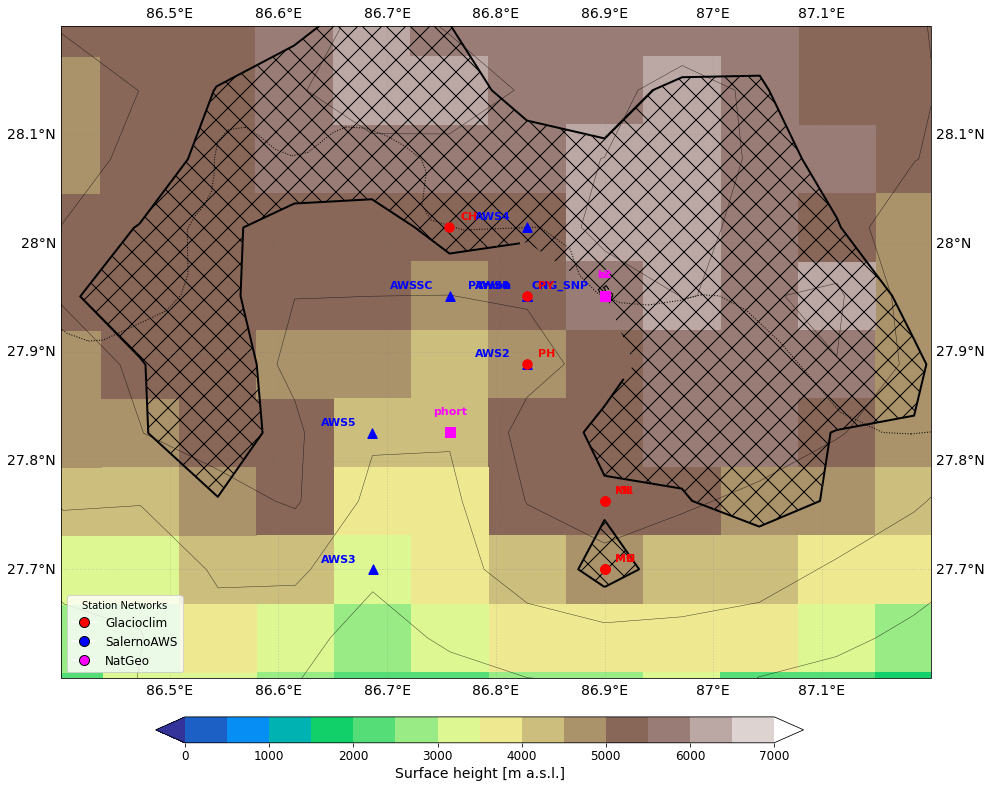

In [18]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.colors as mcolors

# --- Colormap setup ---
clevs = np.arange(0, 7500, 500)
cmap_mod = plt.get_cmap("terrain")
norm = mcolors.BoundaryNorm(boundaries=clevs, ncolors=cmap_mod.N, extend="both")

# --- Figure and axes ---
fig, ax = plt.subplots(figsize=(18, 12),
                       subplot_kw={'projection': ccrs.PlateCarree()})

# --- Shading and elevation contours ---
im = ax.pcolormesh(LONS, LATS, dsSH, cmap=cmap_mod, norm=norm,
                   transform=ccrs.PlateCarree(), shading="auto")
ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, linestyle=':')

# --- ICE overlay ---
ax.contourf(LONS, LATS, dsICE, levels=[10, 50, 100],
            hatches=['', 'X', 'X'], colors="none", transform=ccrs.PlateCarree())

# --- Elevation contours ---
SH1 = ax.contour(LONS, LATS, dsSH,
                 levels=[1000, 2000, 3000, 4000, 5000, 6000, 7000],
                 colors="k", linewidths=0.5, alpha=0.7,
                 transform=ccrs.PlateCarree())
ax.clabel(SH1, inline=True, fontsize=12, fmt="%d")

# --- Glacier mask contour ---
ICE2 = ax.contour(LONS, LATS, dsICE,
                  levels=[50], colors="black", linewidths=2.0,
                  transform=ccrs.PlateCarree())
ax.clabel(ICE2, inline=True, fontsize=14, fmt="%d")

# --- Map extent and gridlines ---
ax.set_extent([86.4, 87.2, 27.6, 28.2], crs=ccrs.PlateCarree())
gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                  linewidth=1, color="gray", alpha=0.3, linestyle=":")
gl.xlabel_style = {"size": 14}
gl.ylabel_style = {"size": 14}

# =====================================================
# === STATION PLOTTING SECTION ===
# =====================================================
# Assign colors and markers for each group
group_style = {
    "Glacioclim": {"color": "red",    "marker": "o", "text_offset": (0.02, 0.01), "ha": "left"},
    "SalernoAWS": {"color": "blue",   "marker": "^", "text_offset": (-0.03, 0.01), "ha": "right"},
    "NatGeo":     {"color": "fuchsia", "marker": "s", "text_offset": (0.00, 0.03), "ha": "center"},
}

group_colors = {
    "Glacioclim": "red",
    "SalernoAWS": "blue",
    "NatGeo": "fuchsia"
}
# Loop through all stations
for name, (lat_sta, lon_sta, group) in stations_all.items():
    style = group_style.get(group, {"color": "gray", "marker": "x", "text_offset": (0.001, 0.001), "ha": "left"})
    color = style["color"]
    marker = style["marker"]
    dx, dy = style["text_offset"]

    j, i = nearest_indices[name]
    lon = LONS[j, i]
    lat = LATS[j, i]

    # Plot station marker
    ax.scatter(lon, lat, marker=marker, color=color, s=90, edgecolor=color,
               transform=ccrs.PlateCarree(), zorder=6)

    # Label text with group-specific offset
    ax.text(lon + dx*0.5, lat + dy*0.5, name,
            fontsize=11, fontweight="bold", color=color,
            ha=style["ha"], va="bottom",
            transform=ccrs.PlateCarree(), zorder=7)


# =====================================================
# === COLORBAR AND LEGEND ===
# =====================================================
cbar_ax = fig.add_axes([0.25, 0.05, 0.5, 0.03])  # [left, bottom, width, height]
cbar = fig.colorbar(im, cax=cbar_ax, orientation="horizontal")
cbar.set_label("Surface height [m a.s.l.]", fontsize=14)
cbar.ax.tick_params(labelsize=12)

# Add legend for station groups
handles = [plt.Line2D([0], [0], marker='o', color='w',
                      markerfacecolor=c, markeredgecolor='k', markersize=10,
                      label=g) for g, c in group_colors.items()]
ax.legend(handles=handles, loc="lower left", fontsize=12,
          title="Station Networks", frameon=True)

# =====================================================
# === SAVE AND SHOW ===
# =====================================================
plotsDir = "/home/santolam/RECAP/figures/paper_on_validation_RECAP/"
plotname = f"FIGX_map_all_stations_MAR.{domain}_SH_ICE_nepal_zoom"
plt.savefig(f"{plotsDir}{plotname}.png", bbox_inches="tight", dpi=300)
print(f" Saved: {plotsDir}{plotname}.png")

plt.show()


Saved: /home/santolam/RECAP/figures/paper_on_validation_RECAP/fig9a_maps_groups_precip_MAR.GRc_SH_ICE_nepal_zoom.png


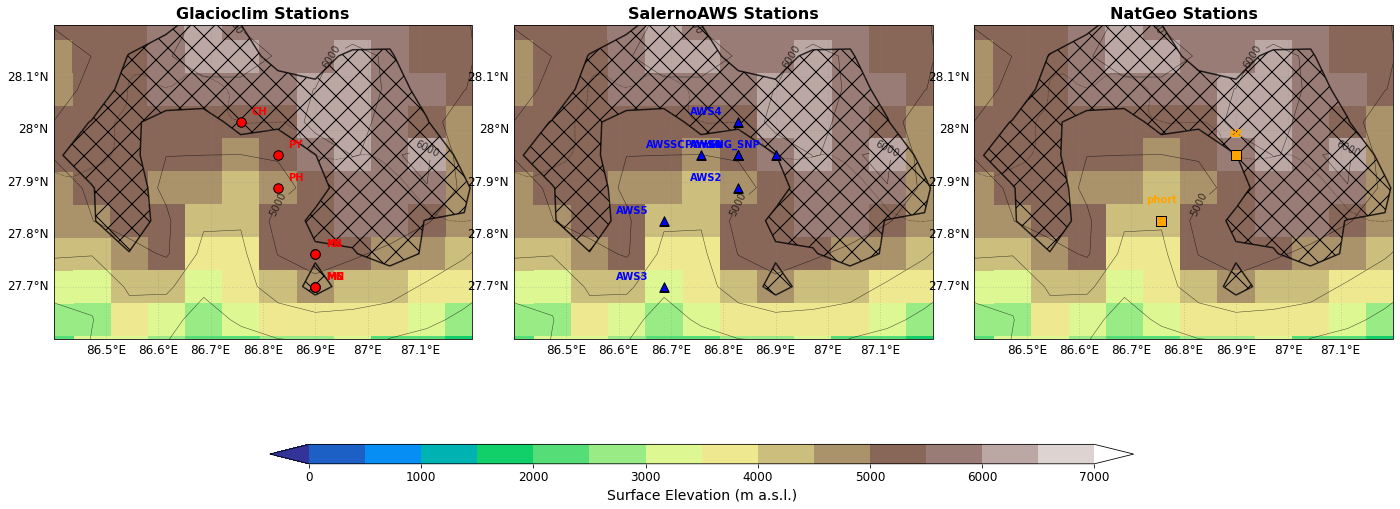

In [19]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# --- Color levels & normalization ---
clevs = np.arange(0, 7500, 500)
cmap_mod = plt.get_cmap('terrain')
norm = mcolors.BoundaryNorm(boundaries=clevs, ncolors=cmap_mod.N, extend="both")

# --- Groups styling ---
group_style = {
    "Glacioclim": {"color": "red",    "marker": "o", "text_offset": (0.02, 0.01), "ha": "left"},
    "SalernoAWS": {"color": "blue",   "marker": "^", "text_offset": (-0.03, 0.01), "ha": "right"},
    "NatGeo":     {"color": "orange", "marker": "s", "text_offset": (0.00, 0.03), "ha": "center"},
}

# --- Create subplots ---
groups = ["Glacioclim", "SalernoAWS", "NatGeo"]
fig, axes = plt.subplots(1, 3, figsize=(24, 9),
                         subplot_kw={'projection': ccrs.PlateCarree()})
for ax, group_name in zip(axes, groups):
    # --- Background map ---
    im = ax.pcolormesh(LONS, LATS, dsSH,
                       transform=ccrs.PlateCarree(),
                       cmap=cmap_mod, norm=norm, shading='auto')

    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linestyle=':', linewidth=0.5)
    ax.set_extent([86.4, 87.2, 27.6, 28.2], crs=ccrs.PlateCarree())
    ax.set_aspect(1.0)

    # --- Elevation contours ---
    SH1 = ax.contour(LONS, LATS, dsSH,
                     levels=[1000,2000,3000,4000,5000,6000,7000],
                     colors="k", linewidths=0.5, alpha=0.7,
                     transform=ccrs.PlateCarree())
    ax.clabel(SH1, inline=True, fontsize=10, fmt="%d")
# --- ICE overlay ---
    ax.contourf(LONS, LATS, dsICE, levels=[10, 50, 100],
            hatches=['', 'X', 'X'], colors="none", transform=ccrs.PlateCarree())

    # --- Ice mask ---
    ax.contour(LONS, LATS, dsICE, levels=[50],
               colors="black", linewidths=1.5, alpha=0.8,
               transform=ccrs.PlateCarree())

    # --- Plot stations of this group ---
    style = group_style[group_name]
    for name, (lat_sta, lon_sta, group) in stations_all.items():
        if group != group_name:
            continue
        j, i = nearest_indices[name]
        lon = LONS[j, i]
        lat = LATS[j, i]
        dx, dy = style["text_offset"]

        # Scatter
        ax.scatter(lon, lat, marker=style["marker"], color=style["color"],
                   s=90, edgecolor="black", transform=ccrs.PlateCarree(), zorder=6)

        # Label
        ax.text(lon + dx, lat + dy, name, fontsize=10, fontweight="bold",
                color=style["color"], ha=style["ha"], va="bottom",
                transform=ccrs.PlateCarree(), zorder=7)

    # --- Gridlines ---
    gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                      linewidth=1, color="gray", alpha=0.3, linestyle=":")
    gl.xlabel_style = {"size": 12}
    gl.ylabel_style = {"size": 12}
    gl.top_labels = gl.right_labels = False

    # --- Title per group ---
    ax.set_title(f"{group_name} Stations", fontsize=16, weight="bold")

# --- Shared colorbar ---
cbar_ax = fig.add_axes([0.25, 0.10, 0.5, 0.03])  # [left, bottom, width, height]
cbar = fig.colorbar(im, cax=cbar_ax, orientation="horizontal")
cbar.set_label("Surface Elevation (m a.s.l.)", fontsize=14)
cbar.ax.tick_params(labelsize=12)

# --- Layout & Save ---
fig.subplots_adjust(wspace=0.1, hspace=0.05, bottom=0.15, top=0.92)
plotsDir = "/home/santolam/RECAP/figures/paper_on_validation_RECAP/"
plotname = f"fig9a_maps_groups_precip_MAR.{domain}_SH_ICE_nepal_zoom"

plt.savefig(f"{plotsDir}{plotname}.png", bbox_inches="tight", dpi=300)
print(f"Saved: {plotsDir}{plotname}.png")
plt.show()


In [20]:
##Glacio
#rr_daily_PY=RR_PY.resample(time='D').sum()
#rr_daily_PH=RR_PH.resample(time='D').sum()
#rr_daily_KH=RR_KH.resample(time='D').sum()

#idatePY = str(rr_daily_PY.time[0].values)[:10]
#fdatePY = str(rr_daily_PY.time[-1].values)[:10]
#idatePH = str(rr_daily_PH.time[0].values)[:10]
#fdatePH = str(rr_daily_PH.time[-1].values)[:10]
#idateKH = str(rr_daily_KH.time[0].values)[:10]
#fdateKH = str(rr_daily_KH.time[-1].values)[:10]

ts_RF_PH=ds_RF[:,jPH,iPH].sel(time=slice(idatePH,fdatePH))
ts_SF_PH=ds_SF[:,jPH,iPH].sel(time=slice(idatePH,fdatePH))
ts_TF_PH=ts_RF_PH+ts_SF_PH

ts_RF_KH=ds_RF[:,jKH,iKH].sel(time=slice(idateKH,fdateKH))
ts_SF_KH=ds_SF[:,jKH,iKH].sel(time=slice(idateKH,fdateKH))
ts_TF_KH=ts_RF_KH+ts_SF_KH


ts_RF_PY=ds_RF[:,jPY,iPY].sel(time=slice(idatePY,fdatePY))
ts_SF_PY=ds_SF[:,jPY,iPY].sel(time=slice(idatePY,fdatePY))
ts_TF_PY=ts_RF_PY+ts_SF_PY


In [21]:
## Salerno
# Daily total precipitation (sum of hourly rates)
#rr_AWS0_daily = df_AWS0['RR'].resample('D').sum()
#rr_AWS1_daily = df_AWS1['RR'].resample('D').sum()
#rr_AWS2_daily = df_AWS2['RR'].resample('D').sum()
#rr_AWS3_daily = df_AWS3['RR'].resample('D').sum()
#rr_AWS4_daily = df_AWS4['RR'].resample('D').sum()
#rr_AWS5_daily = df_AWS5['RR'].resample('D').sum()
#jAWS0, iAWS0 
# --- Define date ranges for each AWS based on observations ---
idate_AWS0 = str(rr_AWS0_daily.index[0].date())
fdate_AWS0 = str(rr_AWS0_daily.index[-1].date())
idate_AWS1 = str(rr_AWS1_daily.index[0].date())
fdate_AWS1 = str(rr_AWS1_daily.index[-1].date())
idate_AWS2 = str(rr_AWS2_daily.index[0].date())
fdate_AWS2 = str(rr_AWS2_daily.index[-1].date())
idate_AWS3 = str(rr_AWS3_daily.index[0].date())
fdate_AWS3 = str(rr_AWS3_daily.index[-1].date())
idate_AWS4 = str(rr_AWS4_daily.index[0].date())
fdate_AWS4 = str(rr_AWS4_daily.index[-1].date())
idate_AWS5 = str(rr_AWS5_daily.index[0].date())
fdate_AWS5 = str(rr_AWS5_daily.index[-1].date())

# --- Compute RF, SF, TF for each AWS station ---
ts_RF_AWS0 = ds_RF[:, jAWS0, iAWS0].sel(time=slice(idate_AWS0, fdate_AWS0))
ts_SF_AWS0 = ds_SF[:, jAWS0, iAWS0].sel(time=slice(idate_AWS0, fdate_AWS0))
ts_TF_AWS0 = ts_RF_AWS0 + ts_SF_AWS0

ts_RF_AWS1 = ds_RF[:, jAWS1, iAWS1].sel(time=slice(idate_AWS1, fdate_AWS1))
ts_SF_AWS1 = ds_SF[:, jAWS1, iAWS1].sel(time=slice(idate_AWS1, fdate_AWS1))
ts_TF_AWS1 = ts_RF_AWS1 + ts_SF_AWS1

ts_RF_AWS2 = ds_RF[:, jAWS2, iAWS2].sel(time=slice(idate_AWS2, fdate_AWS2))
ts_SF_AWS2 = ds_SF[:, jAWS2, iAWS2].sel(time=slice(idate_AWS2, fdate_AWS2))
ts_TF_AWS2 = ts_RF_AWS2 + ts_SF_AWS2

ts_RF_AWS3 = ds_RF[:, jAWS3, iAWS3].sel(time=slice(idate_AWS3, fdate_AWS3))
ts_SF_AWS3 = ds_SF[:, jAWS3, iAWS3].sel(time=slice(idate_AWS3, fdate_AWS3))
ts_TF_AWS3 = ts_RF_AWS3 + ts_SF_AWS3

ts_RF_AWS4 = ds_RF[:, jAWS4, iAWS4].sel(time=slice(idate_AWS4, fdate_AWS4))
ts_SF_AWS4 = ds_SF[:, jAWS4, iAWS4].sel(time=slice(idate_AWS4, fdate_AWS4))
ts_TF_AWS4 = ts_RF_AWS4 + ts_SF_AWS4

ts_RF_AWS5 = ds_RF[:, jAWS5, iAWS5].sel(time=slice(idate_AWS5, fdate_AWS5))
ts_SF_AWS5 = ds_SF[:, jAWS5, iAWS5].sel(time=slice(idate_AWS5, fdate_AWS5))
ts_TF_AWS5 = ts_RF_AWS5 + ts_SF_AWS5


In [22]:
##Nat geo
##
#rr_bc_daily = df_bc['PRECIP'].resample('D').sum()
#rr_phort_daily = df_phort['PRECIP'].resample('D').sum()
idate_bc     = str(rr_bc_daily.index[0].date())
fdate_bc     = str(rr_bc_daily.index[-1].date())

idate_phort  = str(rr_phort_daily.index[0].date())
fdate_phort  = str(rr_phort_daily.index[-1].date())

ts_RF_bc = ds_RF[:, jbc, ibc].sel(time=slice(idate_bc, fdate_bc))
ts_SF_bc = ds_SF[:, jbc, ibc].sel(time=slice(idate_bc, fdate_bc))
ts_TF_bc = ts_RF_bc + ts_SF_bc

# --- Phortse ---
ts_RF_phort = ds_RF[:, jphort, iphort].sel(time=slice(idate_phort, fdate_phort))
ts_SF_phort = ds_SF[:, jphort, iphort].sel(time=slice(idate_phort, fdate_phort))
ts_TF_phort = ts_RF_phort + ts_SF_phort


 Saved: /home/santolam/RECAP/figures/paper_on_validation_RECAP/FIGSX_round2_timeseries_daily_pre.glacioclim_MAR.GRc.png


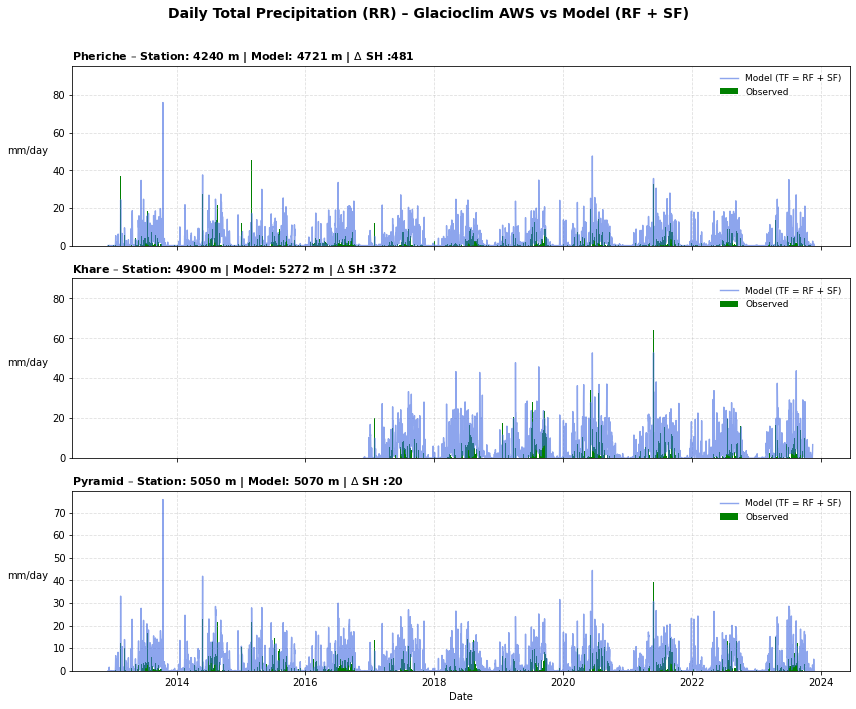

In [23]:
import matplotlib.pyplot as plt

# --- Observed daily precipitation series ---
stations_rr_daily_glacioclim = {
    "Pheriche": rr_daily_PH,
    "Khare": rr_daily_KH,
    "Pyramid": rr_daily_PY
}

# --- Model total fall (rain + snow) ---
ts_TF_model_glacioclim = {
    "Pheriche": ts_TF_PH,
    "Khare": ts_TF_KH,
    "Pyramid": ts_TF_PY
}

# --- Station elevations (manually defined or from metadata) ---
elev_station_glacioclim = {
    "Pheriche": 4240,  # m
    "Khare": 4900,
    "Pyramid": 5050
}

# --- Model elevations from dsSH field ---
elev_model_glacioclim = {
    "Pheriche": float(dsSH[jPH, iPH]),
    "Khare": float(dsSH[jKH, iKH]),
    "Pyramid": float(dsSH[jPY, iPY])
}

# --- Create subplots (one per station) ---
fig, axes = plt.subplots(len(stations_rr_daily_glacioclim), 1, figsize=(12, 10), sharex=True)

# --- Plot each station ---
for ax, (name, obs_series) in zip(axes, stations_rr_daily_glacioclim.items()):
    # Observed daily precipitation (bars)
    ax.bar(obs_series.time.values, obs_series.values, color='green', width=1.0,  label="Observed")

    # Model total precipitation (line)
    model_series = ts_TF_model_glacioclim[name].to_pandas()
    ax.plot(model_series.index, model_series, color='royalblue', lw=1.4,alpha=0.6, label="Model (TF = RF + SF)")

    # Elevations
    st_elev = elev_station_glacioclim[name]
    mod_elev = elev_model_glacioclim[name]
    diff_elev=mod_elev-st_elev
    # Style + Title
    ax.set_ylabel("mm/day", rotation=0, labelpad=25)
    ax.set_title(f"{name} – Station: {st_elev:.0f} m | Model: {mod_elev:.0f} m | $\Delta$ SH :{diff_elev:.0f} ",
                 loc='left', fontsize=11, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend(frameon=False, loc='upper right', fontsize=9)

# Shared labels and figure title
axes[-1].set_xlabel("Date")
fig.suptitle("Daily Total Precipitation (RR) – Glacioclim AWS vs Model (RF + SF)",
             fontsize=14, fontweight='bold')

plt.tight_layout(rect=[0, 0, 1, 0.97])
plotsDir = "/home/santolam/RECAP/figures/paper_on_validation_RECAP/"
plotname = f"FIGSX_round2_timeseries_daily_pre.glacioclim_MAR.{domain}"
plt.savefig(f"{plotsDir}{plotname}.png", bbox_inches="tight", dpi=300)
print(f" Saved: {plotsDir}{plotname}.png")


plt.show()


In [24]:
#rr_daily_PH

In [25]:
stations_rr_daily_glacioclim = {
    "Pheriche": rr_daily_PH,
    "Khare": rr_daily_KH,
    "Pyramid": rr_daily_PY
}

elev_station_glacioclim = {
    "Pheriche": 4240,  # m
    "Khare": 4900,
    "Pyramid": 5050
}

jjas_months = [6, 7, 8, 9]
year = 2016  # <-- selected year

print(f"JJAS means for {year}:")
for station, ds in stations_rr_daily_glacioclim.items():
    
    JJAS_year = ds.sel(time=slice(f"{year}-06-01", f"{year}-09-30"))
    JJAS_year_mean = JJAS_year.mean(dim="time")
    
    print(f"{station}','{elev_station_glacioclim[station]}','{float(JJAS_year_mean.values):.2f}")

JJAS means for 2016:
Pheriche','4240','3.33
Khare','4900','nan
Pyramid','5050','4.02


In [26]:
#JJAS_year_PH=rr_daily_PH.sel(time=slice(str(year)+"-06-01",str(year)+"-09-30"))
#JJAS_year_PH_mean=JJAS_year_PH.mean(dim='time')
#JJAS_year_PH_mean

 Saved: /home/santolam/RECAP/figures/paper_on_validation_RECAP/FIGSX_round2_timeseries_daily_pre.salerno_MAR.GRc.png


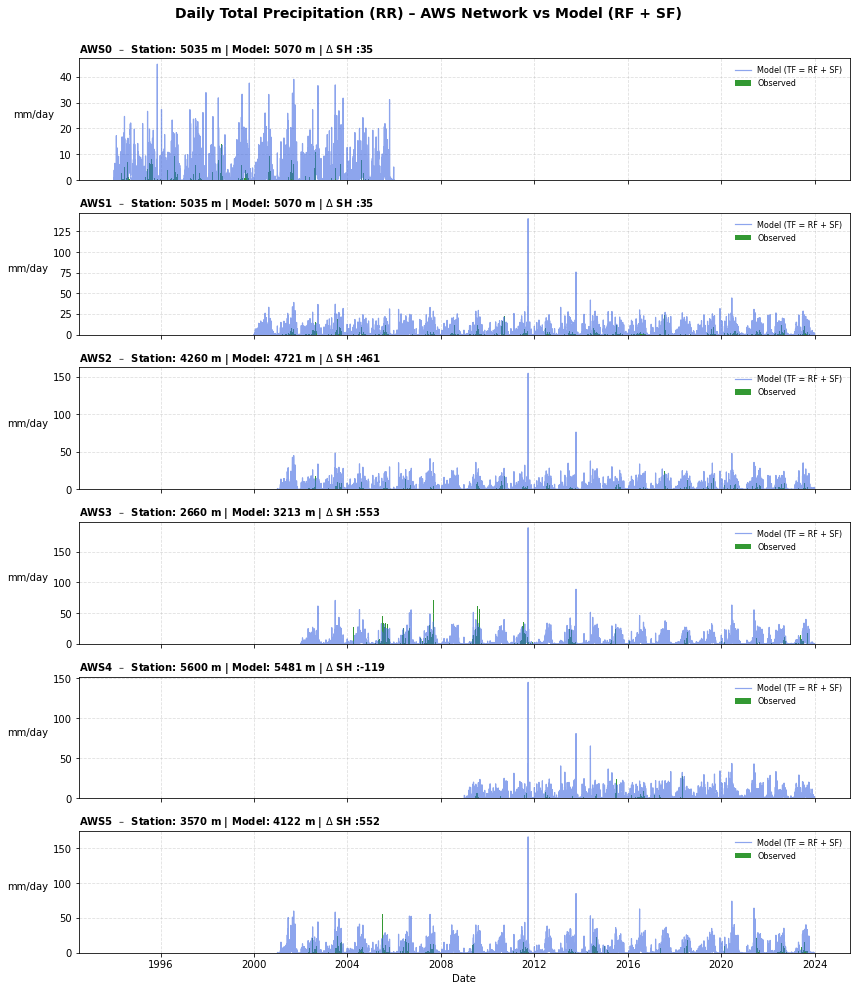

In [27]:
# --- Observed daily total precipitation ---
stations_rr_daily_salerno = {
    "AWS0": rr_AWS0_daily,
    "AWS1": rr_AWS1_daily,
    "AWS2": rr_AWS2_daily,
    "AWS3": rr_AWS3_daily,
    "AWS4": rr_AWS4_daily,
    "AWS5": rr_AWS5_daily,
}

# --- Model total fall (rain + snow) for each AWS station ---
ts_TF_model_salerno = {
    "AWS0": ts_TF_AWS0,
    "AWS1": ts_TF_AWS1,
    "AWS2": ts_TF_AWS2,
    "AWS3": ts_TF_AWS3,
    "AWS4": ts_TF_AWS4,
    "AWS5": ts_TF_AWS5,
}

# --- Station elevation (m) ---
elev_station_salerno = {
    "AWS0": elev_AWS0,
    "AWS1": elev_AWS1,
    "AWS2": elev_AWS2,
    "AWS3": elev_AWS3,
    "AWS4": elev_AWS4,
    "AWS5": elev_AWS5,
}

# --- Model grid elevation (from your elevation field, e.g. field_SH) ---
elev_model_salerno = {
    "AWS0": float(dsSH[jAWS0, iAWS0]),
    "AWS1": float(dsSH[jAWS1, iAWS1]),
    "AWS2": float(dsSH[jAWS2, iAWS2]),
    "AWS3": float(dsSH[jAWS3, iAWS3]),
    "AWS4": float(dsSH[jAWS4, iAWS4]),
    "AWS5": float(dsSH[jAWS5, iAWS5]),
}

# --- Create subplots ---
fig, axes = plt.subplots(len(stations_rr_daily_salerno), 1, figsize=(12, 14), sharex=True)

# --- Plot each AWS station ---
for ax, (name, obs_series) in zip(axes, stations_rr_daily_salerno.items()):
    # Plot observed daily precipitation (bars)
    ax.bar(obs_series.index, obs_series, color='green', width=1.0, alpha=0.8, label="Observed")

    # Plot model total precipitation (line)
    model_series = ts_TF_model_salerno[name].to_pandas()
    ax.plot(model_series.index, model_series, color='royalblue', lw=1.2, alpha=0.6,label="Model (TF = RF + SF)")

    # Elevations
    st_elev = elev_station_salerno[name]
    mod_elev = elev_model_salerno[name]
    diff_elev=mod_elev-st_elev

    # Style + Title with elevations
    ax.set_ylabel("mm/day", rotation=0, labelpad=25)
    ax.set_title(f"{name}  –  Station: {st_elev:.0f} m | Model: {mod_elev:.0f} m | $\Delta$ SH :{diff_elev:.0f} ",
                 loc='left', fontsize=10, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend(frameon=False, loc='upper right', fontsize=8)

# --- Shared x-axis label ---
axes[-1].set_xlabel("Date")

# --- Global figure title ---
fig.suptitle("Daily Total Precipitation (RR) – AWS Network vs Model (RF + SF)",
             fontsize=14, fontweight='bold')

plt.tight_layout(rect=[0, 0, 1, 0.98])
plotsDir = "/home/santolam/RECAP/figures/paper_on_validation_RECAP/"
plotname = f"FIGSX_round2_timeseries_daily_pre.salerno_MAR.{domain}"
plt.savefig(f"{plotsDir}{plotname}.png", bbox_inches="tight", dpi=300)
print(f" Saved: {plotsDir}{plotname}.png")


plt.show()


In [28]:
# If your DataFrame is called df
max_date = ts_TF_AWS2.idxmax()
max_value = ts_TF_AWS2.max()

print("Maximum precipitation:", max_value)
print("Occurred on:", max_date)


Maximum precipitation: <xarray.DataArray ()>
array(154.60110474)
Coordinates:
    X        float32 -7.0
    Y        float32 21.0
Occurred on: <xarray.DataArray 'time' ()>
array('2011-09-26T12:00:00.000000000', dtype='datetime64[ns]')
Coordinates:
    X        float32 -7.0
    Y        float32 21.0


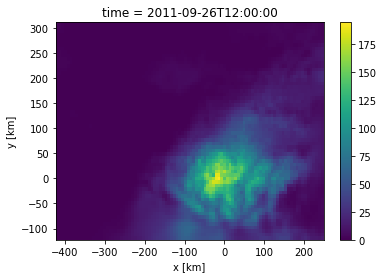

In [47]:
ds_TF.sel(time='2011-09-26').plot()

In [48]:
#
ds_obs=xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/chirps/daily/chirps-v2.0.2011.days_p05_HMA.nc')

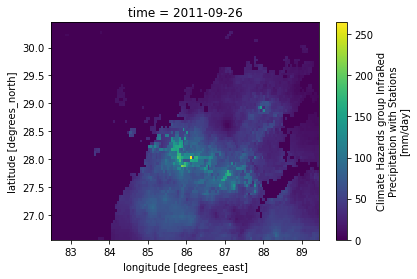

In [57]:
ds_obs.precip.sel(time='2011-09-26',longitude=slice(lon_min,lon_max),latitude=slice(lat_min,lat_max)).plot()

In [29]:
#rr_AWS0_daily

In [30]:
stations_rr_daily_salerno = {
    "AWS0": rr_AWS0_daily,
    "AWS1": rr_AWS1_daily,
    "AWS2": rr_AWS2_daily,
    "AWS3": rr_AWS3_daily,
    "AWS4": rr_AWS4_daily,
    "AWS5": rr_AWS5_daily,
}


# --- Station elevation (m) ---
elev_station_salerno = {
    "AWS0": elev_AWS0,
    "AWS1": elev_AWS1,
    "AWS2": elev_AWS2,
    "AWS3": elev_AWS3,
    "AWS4": elev_AWS4,
    "AWS5": elev_AWS5,
}

#

jjas_months = [6, 7, 8, 9]
year = 2016  # <-- selected year

print(f"JJAS means for {year}:")
for station, series in stations_rr_daily_salerno.items():

    # Select the JJAS period using pandas datetime index
    JJAS_year = series.loc[f"{year}-06-01":f"{year}-09-30"]

    # Compute mean
    JJAS_year_mean = JJAS_year.mean()

    print(f"{station}','{elev_station_salerno[station]}','{JJAS_year_mean:.2f}")


JJAS means for 2016:
AWS0','5035','nan
AWS1','5035','3.41
AWS2','4260','3.03
AWS3','2660','0.00
AWS4','5600','4.25
AWS5','3570','0.00


In [31]:
rr_phort_daily[rr_phort_daily < -100] = np.nan

 Saved: /home/santolam/RECAP/figures/paper_on_validation_RECAP/FIGSX_round2_timeseries_daily_pre.natgeo_MAR.GRc.png


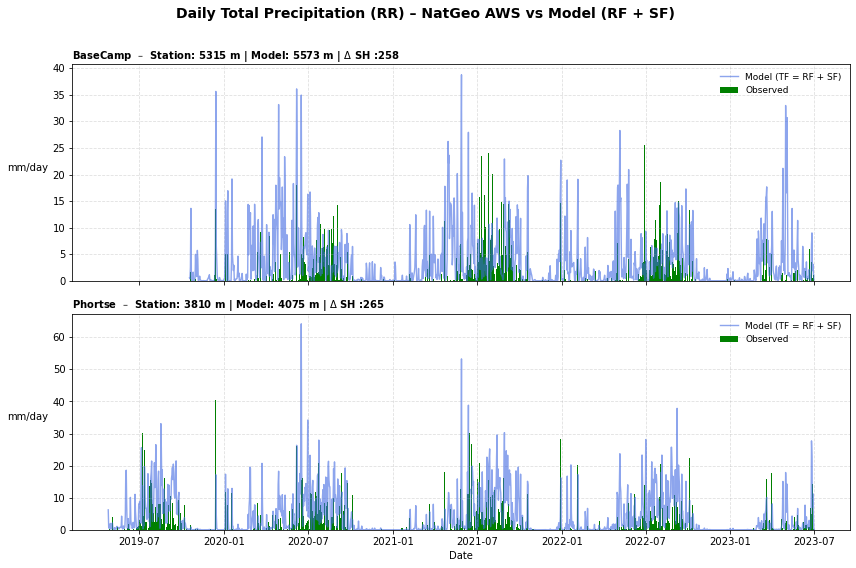

In [32]:

# --- Observed daily total precipitation ---
stations_rr_daily_natgeo = {
    "BaseCamp": rr_bc_daily,
    "Phortse": rr_phort_daily,
}

# --- Model total fall (rain + snow) for each station ---
ts_TF_model_natgeo = {
    "BaseCamp": ts_TF_bc,
    "Phortse": ts_TF_phort,
}

# --- Station elevation (from your metadata) ---
elev_station_natgeo = {
    "BaseCamp": 5315,  # from your stations_info_everest
    "Phortse": 3810,
}

# --- Model grid elevation (from your elevation field) ---
elev_model_natgeo = {
    "BaseCamp": float(dsSH[jbc, ibc]),
    "Phortse": float(dsSH[jphort, iphort]),
}

# --- Create subplots ---
fig, axes = plt.subplots(len(stations_rr_daily_natgeo), 1, figsize=(12, 8), sharex=True)

# --- Plot each NatGeo station ---
for ax, (name, obs_series) in zip(axes, stations_rr_daily_natgeo.items()):
    # Observed daily precipitation (bars)
    ax.bar(obs_series.index, obs_series, color='green', width=1.0, alpha=1.0, label="Observed")

    # Model total precipitation (line)
    model_series = ts_TF_model_natgeo[name].to_pandas()
    ax.plot(model_series.index, model_series, color='royalblue', lw=1.4,alpha=0.6, label="Model (TF = RF + SF)")

    # Elevations
    st_elev = elev_station_natgeo[name]
    mod_elev = elev_model_natgeo[name]
    diff_elev=mod_elev-st_elev
    
    # Style + Title
    ax.set_ylabel("mm/day", rotation=0, labelpad=25)
    ax.set_title(f"{name}  –  Station: {st_elev:.0f} m | Model: {mod_elev:.0f} m | $\Delta$ SH :{diff_elev:.0f} ",
                 loc='left', fontsize=10, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend(frameon=False, loc='upper right', fontsize=9)

# Shared labels and title
axes[-1].set_xlabel("Date")
fig.suptitle("Daily Total Precipitation (RR) – NatGeo AWS vs Model (RF + SF) ",
             fontsize=14, fontweight='bold')

plt.tight_layout(rect=[0, 0, 1, 0.97])
plotsDir = "/home/santolam/RECAP/figures/paper_on_validation_RECAP/"
plotname = f"FIGSX_round2_timeseries_daily_pre.natgeo_MAR.{domain}"
plt.savefig(f"{plotsDir}{plotname}.png", bbox_inches="tight", dpi=300)
print(f" Saved: {plotsDir}{plotname}.png")


plt.show()


In [33]:
#rmse,bias,r
import numpy as np
from scipy.stats import pearsonr

print("=== glacioclim Stations – TF vs Observations ===\n")
bias_list_glacioclim = []
rmse_list_glacioclim = []
corr_list_glacioclim = []
names_glacioclim= []
rbias_list_glacioclim=[]

for name in stations_rr_daily_glacioclim.keys():
    # Observed series
    obs = stations_rr_daily_glacioclim[name]

    # Model series (original)
    mod = ts_TF_model_glacioclim[name].to_pandas()
        
    # Mask model where obs is NaN
    mask = ~np.isnan(obs.values)
    obs_masked = obs.values[mask]
    mod_masked = mod.values[mask]
    mean_obs = np.mean(obs_masked)
    
    # --- Original model ---
    rmse = np.sqrt(np.mean((mod_masked - obs_masked)**2))
    bias = np.mean(mod_masked - obs_masked)
    corr = pearsonr(mod_masked, obs_masked)[0]
    rbias = (bias / mean_obs) * 100.0

    print(f"{name}  | Original: RMSE={rmse:.2f}, Bias={bias:.2f}, R={corr:.2f}  ")
    # Store
    bias_list_glacioclim.append(bias)
    rmse_list_glacioclim.append(rmse)
    corr_list_glacioclim.append(corr)
    names_glacioclim.append(name)
    rbias_list_glacioclim.append(rbias)
 


=== glacioclim Stations – TF vs Observations ===

Pheriche  | Original: RMSE=5.07, Bias=1.62, R=0.45  
Khare  | Original: RMSE=7.46, Bias=2.85, R=0.40  
Pyramid  | Original: RMSE=5.08, Bias=1.67, R=0.44  


In [34]:
print("=== Salerno Stations – TF vs Observations ===\n")
bias_list_salerno = []
rmse_list_salerno = []
corr_list_salerno = []
names_salerno = []
rbias_list_salerno=[]

for name in stations_rr_daily_salerno.keys():
    # Observed series
    obs = stations_rr_daily_salerno[name]

    # Model series (original)
    mod = ts_TF_model_salerno[name].to_pandas()
     
    # Mask model where obs is NaN
    mask = ~np.isnan(obs.values)
    obs_masked = obs.values[mask]
    mod_masked = mod.values[mask]
    mean_obs = np.mean(obs_masked)
    
    # --- Original model ---
    rmse = np.sqrt(np.mean((mod_masked - obs_masked)**2))
    bias = np.mean(mod_masked - obs_masked)
    corr = pearsonr(mod_masked, obs_masked)[0]
    rbias = (bias / mean_obs) * 100.0
    
    print(f"{name}  | Original: RMSE={rmse:.2f}, Bias={bias:.2f}, R={corr:.2f}  ")
    
    # Store
    bias_list_salerno.append(bias)
    rmse_list_salerno.append(rmse)
    corr_list_salerno.append(corr)
    names_salerno.append(name)
    rbias_list_salerno.append(rbias)

=== Salerno Stations – TF vs Observations ===

AWS0  | Original: RMSE=5.40, Bias=2.29, R=0.30  
AWS1  | Original: RMSE=5.61, Bias=2.23, R=0.28  
AWS2  | Original: RMSE=5.51, Bias=2.02, R=0.35  
AWS3  | Original: RMSE=8.18, Bias=1.58, R=0.25  
AWS4  | Original: RMSE=6.33, Bias=2.89, R=0.09  
AWS5  | Original: RMSE=7.38, Bias=2.43, R=0.33  


In [35]:
print("=== natgeo Stations – TF vs Observations ===\n")
# --- Initialize lists for Salerno group ---
bias_list_natgeo = []
rmse_list_natgeo = []
corr_list_natgeo = []
names_natgeo = []
rbias_list_natgeo=[]

for name in stations_rr_daily_natgeo.keys():
    # Observed series
    obs = stations_rr_daily_natgeo[name]

    # Model series (original)
    mod = ts_TF_model_natgeo[name].to_pandas()
     # Mask model where obs is NaN
    mask = ~np.isnan(obs.values)
    obs_masked = obs.values[mask]
    mod_masked = mod.values[mask]
    mean_obs = np.mean(obs_masked)
    
    # --- Original model ---
    rmse = np.sqrt(np.mean((mod_masked - obs_masked)**2))
    bias = np.mean(mod_masked - obs_masked)
    corr = pearsonr(mod_masked, obs_masked)[0]
    rbias = (bias / mean_obs) * 100.0
    
    print(f"{name}  | Original: RMSE={rmse:.2f}, Bias={bias:.2f}, R={corr:.2f}  ")
    
    # Store
    bias_list_natgeo.append(bias)
    rmse_list_natgeo.append(rmse)
    corr_list_natgeo.append(corr)
    names_natgeo.append(name)
    rbias_list_natgeo.append(rbias)

=== natgeo Stations – TF vs Observations ===

BaseCamp  | Original: RMSE=5.53, Bias=1.88, R=0.32  
Phortse  | Original: RMSE=5.99, Bias=1.71, R=0.49  


In [36]:
rbias_list_natgeo

[129.90120248804405, 81.99321890868634]

/tmp/ipykernel_1995890/544211827.py:39: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


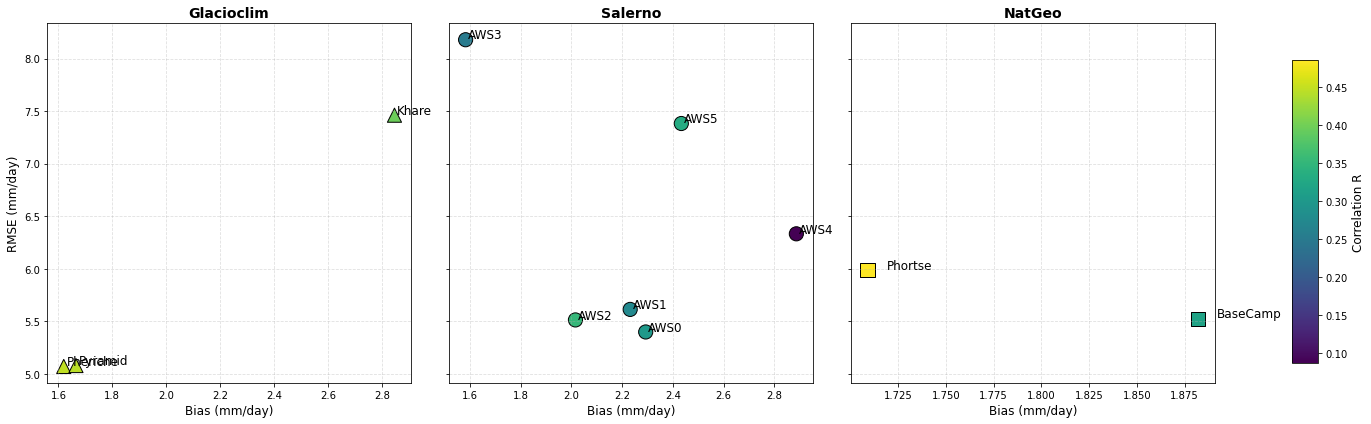

In [37]:
# Groups
groups = ['Glacioclim', 'Salerno', 'NatGeo']
bias_lists = [bias_list_glacioclim, bias_list_salerno, bias_list_natgeo]
rbias_lists = [rbias_list_glacioclim, rbias_list_salerno, rbias_list_natgeo]

rmse_lists = [rmse_list_glacioclim, rmse_list_salerno, rmse_list_natgeo]
corr_lists = [corr_list_glacioclim, corr_list_salerno, corr_list_natgeo]
names_lists = [names_glacioclim, names_salerno, names_natgeo]
markers = ['^', 'o', 's']

# Compute global min and max for correlations (for consistent color scale)
all_corr = np.array(corr_list_glacioclim + corr_list_salerno + corr_list_natgeo)
vmin, vmax = all_corr.min(), all_corr.max()

fig, axes = plt.subplots(1, 3, figsize=(18,6), sharey=True)

for ax, group, bias_list, rmse_list, corr_list, names, marker in zip(
    axes, groups, bias_lists, rmse_lists, corr_lists, names_lists, markers
):
    sc = ax.scatter(
        bias_list, rmse_list, c=corr_list, s=200, cmap='viridis', edgecolor='k', marker=marker,
        vmin=vmin, vmax=vmax
    )
    # Annotate station names
    for i, name in enumerate(names):
        ax.text(bias_list[i]+0.01, rmse_list[i]+0.01, name, fontsize=12)

    ax.set_xlabel('Bias (mm/day)', fontsize=12)
    ax.set_title(group, fontsize=14, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.4)

axes[0].set_ylabel('RMSE (mm/day)', fontsize=12)

# Shared colorbar
cax = fig.add_axes([1.0, 0.15, 0.02, 0.7])  # x, y, width, height
cbar = fig.colorbar(sc, cax=cax, orientation='vertical')
cbar.set_label('Correlation R', fontsize=12)

plt.tight_layout()
plt.show()


In [38]:
names_lists

[['Pheriche', 'Khare', 'Pyramid'],
 ['AWS0', 'AWS1', 'AWS2', 'AWS3', 'AWS4', 'AWS5'],
 ['BaseCamp', 'Phortse']]

Saved: /home/santolam/RECAP/figures/paper_on_validation_RECAP/FIGX_round1_pre.stations_GRq.png


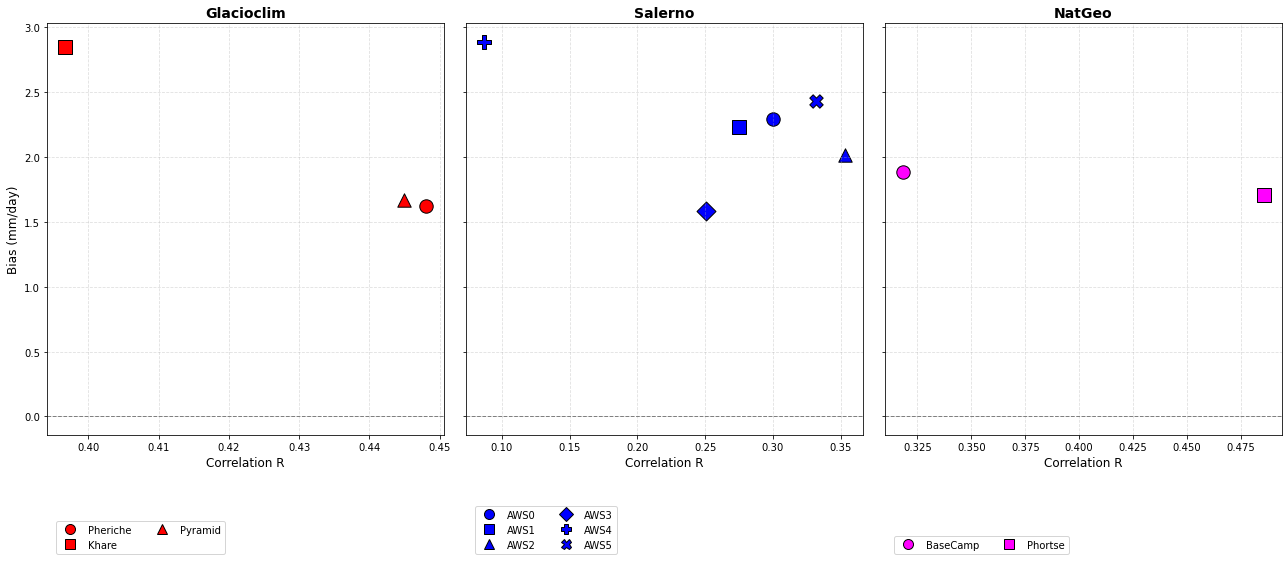

In [39]:
from matplotlib.lines import Line2D   # ← ADD THIS

# Color rules: original only (no correction for precipitation)
color_orig = ['red', 'blue', 'fuchsia']

# One marker per station (cycling)
station_markers = ['o', 's', '^', 'D', 'P', 'X', '*']

fig, axes = plt.subplots(1, 3, figsize=(18,8),sharey=True)

for ax, group, bias_list, corr_list, names, col_o in zip(
        axes, groups, bias_lists, corr_lists, names_lists, color_orig):

    legend_handles = []

    # ---- Plot each station ----
    for i, name in enumerate(names):

        marker = station_markers[i % len(station_markers)]

        ax.scatter(
            corr_list[i], bias_list[i],
            s=180, color=col_o, edgecolor='k', marker=marker
        )

        # Legend entry for this station
        legend_handles.append(
            Line2D([0], [0], marker=marker, linestyle='None',
                   markersize=10, markerfacecolor=col_o,
                   markeredgecolor='k', label=name)
        )

    # ---- Formatting ----
    ax.set_xlabel('Correlation R', fontsize=12)
    ax.set_title(group, fontsize=14, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.axhline(0, color='gray', linestyle='--', linewidth=1)

    # ---- Legend for this subplot ----
    ax.legend(
        handles=legend_handles,
        fontsize=10,
        frameon=True,
        loc='lower left',
        bbox_to_anchor=(0.01, -0.30),
        ncol=2
    )

axes[0].set_ylabel('Bias (mm/day)', fontsize=12)

plt.tight_layout()

plotsDir = "/home/santolam/RECAP/figures/paper_on_validation_RECAP/"
plotname = f'FIGX_round1_pre.stations_{domainM}'
plt.savefig(f"{plotsDir}{plotname}.png", bbox_inches="tight", dpi=300)
print(f"Saved: {plotsDir}{plotname}.png")

plt.show()


Saved: /home/santolam/RECAP/figures/paper_on_validation_RECAP/FIGX_round1_pre.stations_oneplot_GRq.png


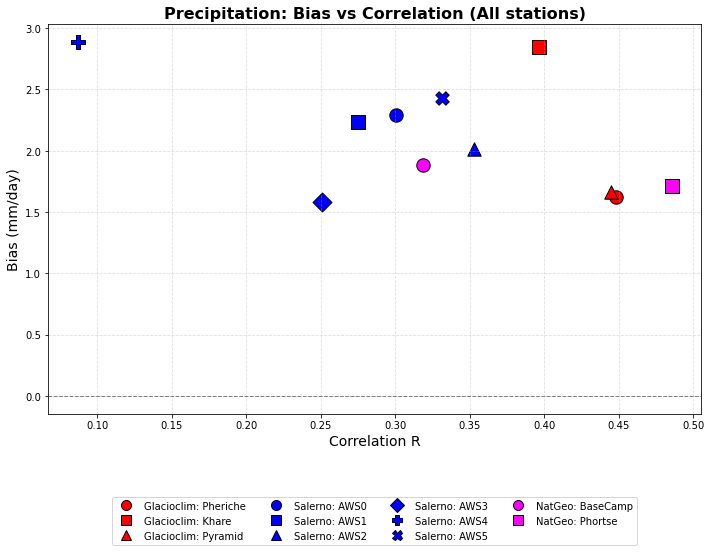

In [40]:
from matplotlib.lines import Line2D

# Color rules per group
color_orig = ['red', 'blue', 'fuchsia']

# One marker per station (cycling)
station_markers = ['o', 's', '^', 'D', 'P', 'X', '*']

fig, ax = plt.subplots(figsize=(10,8))

legend_handles = []     # accumulate for global legend
added = set()           # avoid duplicates in legend

# Loop over groups and their data
for group, bias_list, corr_list, names, col_o in zip(
        groups, bias_lists, corr_lists, names_lists, color_orig):

    for i, name in enumerate(names):

        marker = station_markers[i % len(station_markers)]

        ax.scatter(
            corr_list[i], bias_list[i],
            s=180, color=col_o, edgecolor='k', marker=marker
        )

        # Build unique legend entry per (group, station)
        key = (name, marker, col_o)
        if key not in added:
            added.add(key)
            legend_handles.append(
                Line2D([0], [0], marker=marker, linestyle='None',
                       markersize=10, markerfacecolor=col_o,
                       markeredgecolor='k', label=f"{group}: {name}")
            )

# ---- Formatting ----
ax.set_xlabel('Correlation R', fontsize=14)
ax.set_ylabel('Bias (mm/day)', fontsize=14)
ax.set_title('Precipitation: Bias vs Correlation (All stations)', fontsize=16, fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.4)
ax.axhline(0, color='gray', linestyle='--', linewidth=1)

# ---- Legend (all stations) ----
ax.legend(
    handles=legend_handles,
    fontsize=10,
    frameon=True,
    loc='lower center',
    bbox_to_anchor=(0.5, -0.35),
    ncol=4
)

plt.tight_layout()

plotsDir = "/home/santolam/RECAP/figures/paper_on_validation_RECAP/"
plotname = f'FIGX_round1_pre.stations_oneplot_{domainM}'
plt.savefig(f"{plotsDir}{plotname}.png", bbox_inches="tight", dpi=300)
print(f"Saved: {plotsDir}{plotname}.png")

plt.show()


In [41]:

elev_stations= [elev_station_glacioclim, elev_station_salerno, elev_station_natgeo]

Saved: /home/santolam/RECAP/figures/paper_on_validation_RECAP/FIGX_round1_pre.stations_elev_color_GRq.png


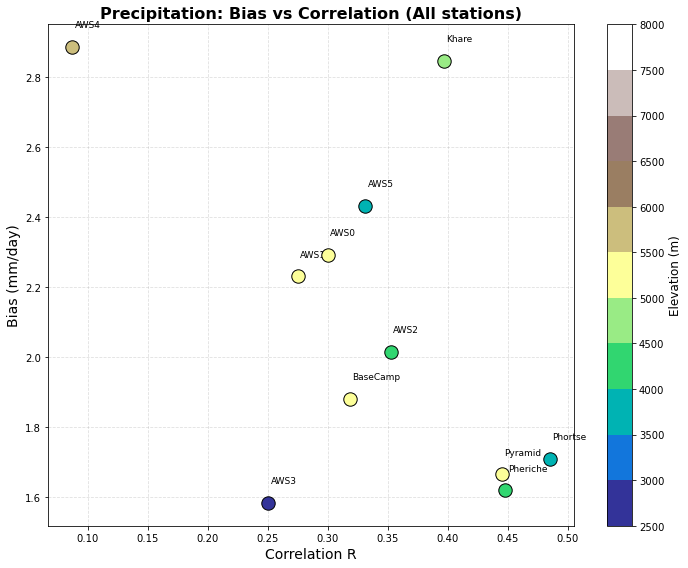

In [42]:
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import cm
from matplotlib.colors import BoundaryNorm

# One marker per station (cycling)
station_markers = ['o', 's', '^', 'D', 'P', 'X', '*']

fig, ax = plt.subplots(figsize=(10,8))

legend_handles = []     # accumulate for global legend
added = set()           # avoid duplicates in legend

# Define discrete elevation bins (example: 500 m intervals)
bins = np.arange(2500, 8500, 500)  # adjust to your station elevations
norm = BoundaryNorm(bins, ncolors=256, clip=True)
cmap = cm.terrain

# Flattened list of station elevations per group
# elev_stations_precip should match the order of stations in names_lists
# Example: elev_stations_precip = [elev_AWS0, elev_AWS1, ..., elev_SouthCol]
elev_idx = 0  # counter for flattened elevation array

# Loop over groups
for group, bias_list, corr_list, names, col_o, elevs in zip(
        groups, bias_lists, corr_lists, names_lists, color_orig, elev_stations
    ):

    for i, name in enumerate(names):
        marker = station_markers[i % len(station_markers)]
        elev = elevs[name]  # get elevation for coloring

        # Scatter point, color depends on elevation
        sc = ax.scatter(
            corr_list[i], bias_list[i],
            s=180, marker='o',
            c=[elev], cmap=cmap, norm=norm,
            edgecolor='k', zorder=5
        )

        # Add station name as text
        ax.text(
            corr_list[i] + 0.002,
            bias_list[i] + 0.05,
            name,
            fontsize=9,
            ha='left',
            va='bottom'
        )

        elev_idx += 1

        # Build unique legend entry per (group, station)
        key = (name, marker, col_o)
        if key not in added:
            added.add(key)
            legend_handles.append(
                Line2D([0], [0], marker=marker, linestyle='None',
                       markersize=10, markerfacecolor=col_o,
                       markeredgecolor='k', label=f"{group}: {name}")
            )

# ---- Formatting ----
ax.set_xlabel('Correlation R', fontsize=14)
ax.set_ylabel('Bias (mm/day)', fontsize=14)
ax.set_title('Precipitation: Bias vs Correlation (All stations)', fontsize=16, fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.4)
#ax.axhline(0, color='gray', linestyle='--', linewidth=1)

# ---- Legend ----
#ax.legend(
#    handles=legend_handles,
#    fontsize=10,
#    frameon=True,
#    loc='lower center',
#    bbox_to_anchor=(0.5, -0.35),
#    ncol=4
#)

# ---- Colorbar for elevation ----
cbar = plt.colorbar(sc, ax=ax, boundaries=bins, ticks=bins)
cbar.set_label('Elevation (m)', fontsize=12)

plt.tight_layout()

plotsDir = "/home/santolam/RECAP/figures/paper_on_validation_RECAP/"
plotname = f'FIGX_round1_pre.stations_elev_color_{domainM}'
plt.savefig(f"{plotsDir}{plotname}.png", bbox_inches="tight", dpi=300)
print(f"Saved: {plotsDir}{plotname}.png")

plt.show()


In [43]:
#              ERA5             HARv2
#              r   Bias SD RMSE r Bias SD RMSE
#P (mm day21) 0.63 0.5 3.7 3.7  0.60 0.9 5.2 5.3
#Pheriche
#P (mm day21) 0.62 1.4 4.6 4.8  0.67 1.1 5.4 5.5
#Khare
#P (mm day21) 0.68 1.8 6.0 6.3  0.66 2.8 8.8 9.2
#Khadka_et_al_2022 (a The subscript i stands for daily means, obtained from hourly values.When the hourly values from the AWS are missing, the corresponding
#hourly values from ERA5L and HARv2 are discarded. The overbar (i.e., x and y) stands for mean values over the entire studied period or
#over each season.)

In [44]:
print('ok')

ok


Saved: /home/santolam/RECAP/figures/paper_on_validation_RECAP/FIGX_round1_pre_elevY_biasX_colorR_groupMarkers_GRq.png


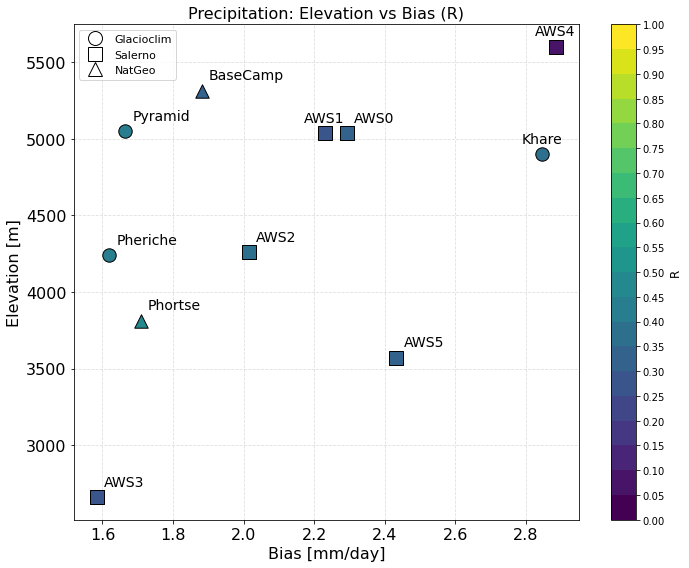

In [45]:
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import cm
from matplotlib.colors import BoundaryNorm

# One marker per group (cycling if needed)
group_markers = ['o', 's', '^', 'D', 'P', 'X', '*']

fig, ax = plt.subplots(figsize=(10,8))

legend_handles = []
added_groups = set()

# Bins for correlation shading
bins = np.arange(0., 1.05, 0.05)
norm = BoundaryNorm(bins, ncolors=256, clip=True)
cmap = cm.viridis

# Loop by group
for gi, (group, bias_list, corr_list, names, col_o, elevs) in enumerate(
    zip(groups, bias_lists, corr_lists, names_lists, color_orig, elev_stations)
):

    marker = group_markers[gi % len(group_markers)]

    for i, name in enumerate(names):
        elev = elevs[name]
        bias = bias_list[i]
        r    = corr_list[i]

        # scatter: x=bias, y=elevation, shading=r, group marker
        sc = ax.scatter(
            bias, elev,
            s=180,
            marker=marker,
            c=[r], cmap=cmap, norm=norm,
            edgecolor='k',
            zorder=5
        )
        if name in ['AWS1','Khare','AWS4']:
            ax.text(
            bias - 0.06,
            elev + 55,
            name,
            fontsize=14,
            ha='left',
            va='bottom'
        )
        else:
        # label for station
            ax.text(
            bias + 0.02,
            elev + 55,
            name,
            fontsize=14,
            ha='left',
            va='bottom'
        )

    # Add only one legend entry per group
    if group not in added_groups:
        added_groups.add(group)
        legend_handles.append(
            Line2D([0], [0], marker=marker, linestyle='None',
                   markersize=14, markerfacecolor='none',
                   markeredgecolor='k', label=group)
        )

# Axes formatting
ax.set_xlabel('Bias [mm/day]', fontsize=16)
ax.set_ylabel('Elevation [m]', fontsize=16)
ax.set_title('Precipitation: Elevation vs Bias (R)',
             fontsize=16)#, fontweight='bold')
ax.tick_params(axis='both', labelsize=16)
ax.grid(True, linestyle='--', alpha=0.4)

# Legend
ax.legend(
    handles=legend_handles,
    fontsize=11,
    frameon=True,
    loc='upper left'
)

# Colorbar for correlation shading
cbar = plt.colorbar(sc, ax=ax, boundaries=bins, ticks=bins)
cbar.set_label('R', fontsize=12)

plt.tight_layout()

plotsDir = "/home/santolam/RECAP/figures/paper_on_validation_RECAP/"
plotname = f'FIGX_round1_pre_elevY_biasX_colorR_groupMarkers_{domainM}'
plt.savefig(f"{plotsDir}{plotname}.png", bbox_inches="tight", dpi=300)
print(f"Saved: {plotsDir}{plotname}.png")

plt.show()


In [46]:
rbias_list

NameError: name 'rbias_list' is not defined

In [ ]:

# One marker per group (cycling if needed)
group_markers = ['o', 's', '^', 'D', 'P', 'X', '*']

fig, ax = plt.subplots(figsize=(10,8))

legend_handles = []
added_groups = set()

# Bins for correlation shading
bins = np.arange(0., 1.05, 0.05)
norm = BoundaryNorm(bins, ncolors=256, clip=True)
cmap = cm.viridis

# Loop by group
for gi, (group, rbias_list, corr_list, names, col_o, elevs) in enumerate(
    zip(groups, rbias_lists, corr_lists, names_lists, color_orig, elev_stations)
):

    marker = group_markers[gi % len(group_markers)]

    for i, name in enumerate(names):
        elev = elevs[name]
        rbias = rbias_list[i]
        r    = corr_list[i]

        # scatter: x=bias, y=elevation, shading=r, group marker
        sc = ax.scatter(
            rbias, elev,
            s=180,
            marker=marker,
            c=[r], cmap=cmap, norm=norm,
            edgecolor='k',
            zorder=5
        )
        if name in ['AWS1','Khare','AWS4']:
            ax.text(
            rbias - 0.06,
            elev + 55,
            name,
            fontsize=14,
            ha='left',
            va='bottom'
        )
        else:
        # label for station
            ax.text(
            rbias + 0.02,
            elev + 55,
            name,
            fontsize=14,
            ha='left',
            va='bottom'
        )

    # Add only one legend entry per group
    if group not in added_groups:
        added_groups.add(group)
        legend_handles.append(
            Line2D([0], [0], marker=marker, linestyle='None',
                   markersize=14, markerfacecolor='none',
                   markeredgecolor='k', label=group)
        )

# Axes formatting
ax.set_xlabel('Relative Bias [%]', fontsize=16)
ax.set_ylabel('Elevation [m]', fontsize=16)
ax.set_title('Precipitation: Elevation vs Bias (R)',
             fontsize=16)#, fontweight='bold')
ax.tick_params(axis='both', labelsize=16)
ax.grid(True, linestyle='--', alpha=0.4)

# Legend
ax.legend(
    handles=legend_handles,
    fontsize=11,
    frameon=True,
    loc='upper left'
)

# Colorbar for correlation shading
cbar = plt.colorbar(sc, ax=ax, boundaries=bins, ticks=bins)
cbar.set_label('R', fontsize=12)

plt.tight_layout()

plotsDir = "/home/santolam/RECAP/figures/paper_on_validation_RECAP/"
plotname = f'FIGX_round1_pre_elevY_biasX_colorR_groupMarkers_{domainM}'
plt.savefig(f"{plotsDir}{plotname}.png", bbox_inches="tight", dpi=300)
print(f"Saved: {plotsDir}{plotname}.png")

plt.show()


In [ ]:
for gi, (group, rbias_list, corr_list, names, col_o, elevs) in enumerate(
    zip(groups, rbias_lists, corr_lists, names_lists, color_orig, elev_stations)
):
    print(rbias_list)